TODO: model on kopio oppikirjasta(tarvitsee lisäyksiä ainakin data augmentation), rgb standardisointia pitää tarkastella, data pitää käydä läpi ja poistaa huonot näytteet. Koulutusta vois yrittää nopeuttaa .

kaikki teksti ja selitykset.

mahdollisia virheitä clasificaatioissa(yritin plotata kuvan ja tod vierekkäin sormia oli pystyssä vaikka 1 ja malli oli arvannut ylivoimaisesti yksi, mutta ohjelma sanoi oikeaksi luokaksi 4. kyse ei ole virheellisestä datasta test/4 kansiossa tarkistin)

sudo apt install git-lfs for linux mint. Might need to download on other os aswell not shure

git lfs install
git lsf pull
wait for the images to download
unzip folders

run the following code
and then you are should have a folder "dataset_split" that has folders "train", "test", "val" that have folders 0,1,2,3,4,5

found bad data (seed=0):
in test/1 1 bad image
in val/2  1 bad image

In [2]:
from pathlib import Path
import random
import shutil

SEED = 0
rng = random.Random(SEED)

source = Path("kuvat")
target = Path("dataset_split")

#removes target if it exist and makes it again so that when this code is rerun with a different seed there will be no problems
if target.exists():
    shutil.rmtree(target)

target.mkdir(parents=True, exist_ok=True)

for class_dir in sorted(source.iterdir()):
    if not class_dir.is_dir():
        continue

    images = sorted(
        p for p in class_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )

    rng.shuffle(images)

    n = len(images)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    splits = {
        "train": images[:n_train],
        "val": images[n_train:n_train + n_val],
        "test": images[n_train + n_val:]
    }

    for split, files in splits.items():
        output_dir = target / split / class_dir.name
        output_dir.mkdir(parents=True, exist_ok=True)

        for file in files:
            shutil.copy2(file, output_dir / file.name)

        print(f"{class_dir.name} | {split}: {len(files)}")

.ipynb_checkpoints | train: 0
.ipynb_checkpoints | val: 0
.ipynb_checkpoints | test: 0
0 | train: 253
0 | val: 54
0 | test: 55
1 | train: 299
1 | val: 64
1 | test: 65
2 | train: 305
2 | val: 65
2 | test: 66
3 | train: 322
3 | val: 69
3 | test: 70
4 | train: 209
4 | val: 44
4 | test: 46
5 | train: 277
5 | val: 59
5 | test: 61


Data pre prosessing
images will be scaled to 244x244 pixels images. 3 rgb values will be scaled to be between 0 and 1 each

In [5]:
import keras
from keras import layers
from keras.utils import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
    "dataset_split/train",
    image_size = (244, 244),
    batch_size = 32)
validation_dataset = image_dataset_from_directory(
    "dataset_split/val",
    image_size = (244, 244),
    batch_size = 32)
test_dataset = image_dataset_from_directory(
    "dataset_split/test",
    image_size = (244, 244),
    batch_size = 32)

Found 1665 files belonging to 6 classes.
Found 355 files belonging to 6 classes.
Found 363 files belonging to 6 classes.


In [6]:
inputs = keras.Input(shape=(244, 244, 3))
# Rescales inputs to the [0, 1] range by dividing them by 255
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=512, kernel_size=3, activation="relu")(x)
# Flattens the 3D activations with shape (height, width, 512) into 1D
# activations with shape (512,) by averaging them over spatial
# dimensions
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(6, activation="softmax")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 244, 244, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 244, 244, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 242, 242, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 121, 121, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 119, 119, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 59, 59, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 57, 57, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,571,654 (6.00 MB)

 Trainable params: 1,571,654 (6.00 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"],
)

history = model.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset
)

Epoch 1/50


/home/user/projects/Neuroverkkoprojekti/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


53/53 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.1820 - loss: 1.7908 - val_accuracy: 0.1944 - val_loss: 1.7852
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.1934 - loss: 1.7855 - val_accuracy: 0.1944 - val_loss: 1.7830
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.1934 - loss: 1.7842 - val_accuracy: 0.1944 - val_loss: 1.7819
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.1844 - loss: 1.7838 - val_accuracy: 0.1944 - val_loss: 1.7822
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.1910 - loss: 1.7830 - val_accuracy: 0.2085 - val_loss: 1.7695
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.1904 - loss: 1.8355 - val_accuracy: 0.2310 - val_loss: 1.7537
Epoch 7/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.2156 - loss: 1.7635 - val_accuracy: 0.2085 - val_loss: 1.7590
Epoch 8/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.2198 - loss: 1.7543 - val_accuracy: 0.1915 - val_loss: 1.7505
Epo

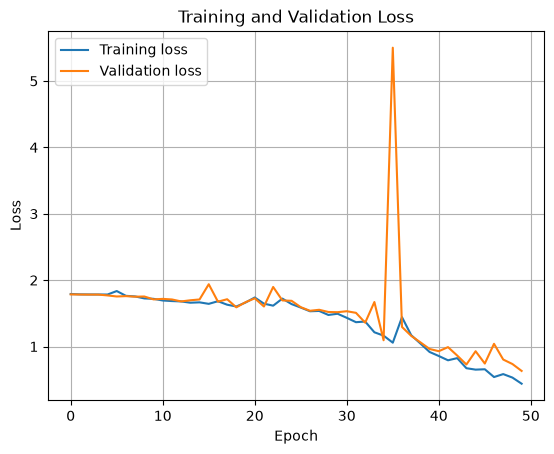

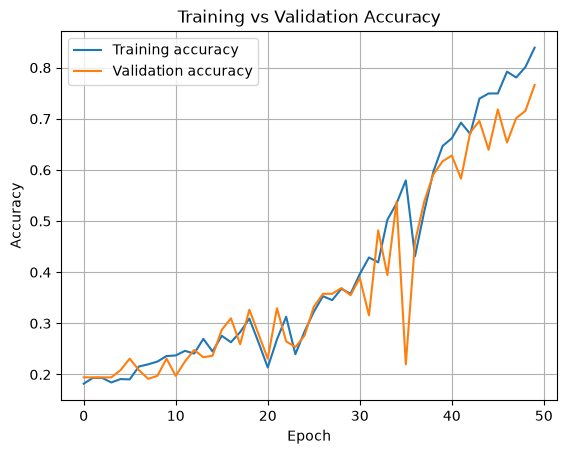

In [10]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()



In [16]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 280ms/step - accuracy: 0.7245 - loss: 0.7156
Test Loss: 0.7155818343162537
Test Accuracy: 0.7245178818702698
